In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_cleaned.csv to customer_churn_cleaned.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("customer_churn_cleaned.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Dataset shape: (7043, 21)
Missing values: 0
Duplicate rows: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].astype(str).str.strip()

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training records: 5634
Testing records: 1409

Training target distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64

Testing target distribution:
Churn
No     1035
Yes     374
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

# Process numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Define three classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

print("\nAll three model pipelines are ready!")

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

All three model pipelines are ready!


In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
fitted_models = {}

for name, pipe in pipelines.items():

    print(f"Training {name}...")

    # Cross-validation on training data only
    cv_scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1
    )

    # Train on the complete training set
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    # Predict on held-out test data
    predictions = pipe.predict(X_test)

    classes = list(pipe.named_steps["model"].classes_)
    yes_index = classes.index("Yes")
    probabilities = pipe.predict_proba(X_test)[:, yes_index]

    results.append({
        "Model": name,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Precision": cv_scores["test_precision"].mean(),
        "CV Recall": cv_scores["test_recall"].mean(),
        "CV F1": cv_scores["test_f1"].mean(),
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Test F1": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(
            (y_test == "Yes").astype(int), probabilities
        )
    })

results_df = pd.DataFrame(results)

print("\nMODEL EVALUATION RESULTS")
display(results_df.round(4))


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...

MODEL EVALUATION RESULTS


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,0.7485,NaN,NaN,NaN,0.7381,0.5043,0.7834,0.6136,0.8416
1,Decision Tree,0.7378,NaN,NaN,NaN,0.7317,0.4946,0.4866,0.4906,0.6537
2,Random Forest,0.7861,NaN,NaN,NaN,0.7828,0.6189,0.4733,0.5364,0.8232


In [ ]:

from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes", zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label="Yes", zero_division=0
    )
}

cv_results = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))


,Model,CV Accuracy,CV Precision,CV Recall,CV F1
0,Logistic Regression,0.7485,0.5169,0.8013,0.6283
1,Decision Tree,0.7378,0.5064,0.4977,0.5019
2,Random Forest,0.7861,0.6288,0.4742,0.5404


              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



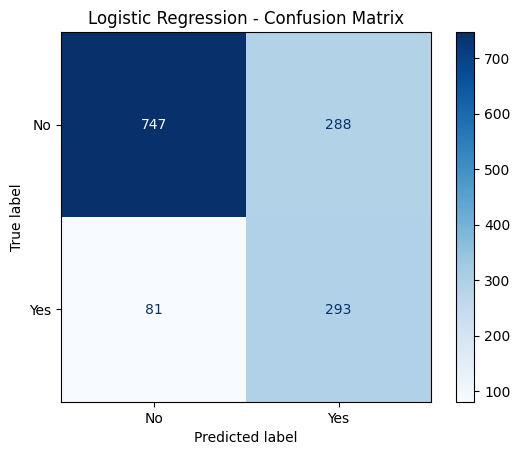

In [7]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

log_model = fitted_models["Logistic Regression"]
log_predictions = log_model.predict(X_test)

print(classification_report(
    y_test,
    log_predictions,
    labels=["No", "Yes"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_predictions,
    labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


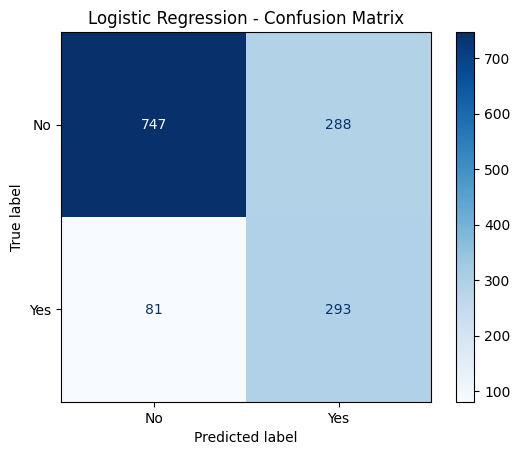

In [8]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_predictions,
    labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [9]:

from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Yes", zero_division=0),
    "f1": make_scorer(f1_score, pos_label="Yes", zero_division=0)
}

cv_results = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))


,Model,CV Accuracy,CV Precision,CV Recall,CV F1
0,Logistic Regression,0.7485,0.5169,0.8013,0.6283
1,Decision Tree,0.7378,0.5064,0.4977,0.5019
2,Random Forest,0.7861,0.6288,0.4742,0.5404
